In [1]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import AdaBoostClassifier
from sklearn.metrics import roc_curve, roc_auc_score

# -------------------------
# 1. Dataset
# -------------------------
X_train = np.array([[1], [2], [3], [8], [9], [10]])
y_train = np.array([0, 0, 0, 1, 1, 1])

X_test = np.array([[4], [5], [6], [7]])
y_test = np.array([0, 0, 1, 1])



In [2]:
X_test

array([[4],
       [5],
       [6],
       [7]])

In [3]:
# -------------------------
# 2. Entrenar AdaBoost
# -------------------------
model = AdaBoostClassifier(
    n_estimators=10,
    random_state=42
)

model.fit(X_train, y_train)


AdaBoostClassifier(n_estimators=10, random_state=42)

In [4]:
y_predicc = model.predict(X_test)
y_predicc

array([0, 0, 1, 1])

In [5]:
# -------------------------
# 3. Obtener probabilidades
# -------------------------
y_prob = model.predict_proba(X_test)[:, 1] #columna 2 son las probabilidades de la clase positiva

print("Probabilidades de la clase positiva:", y_prob)

Probabilidades de la clase positiva: [0.11920292 0.11920292 0.88079708 0.88079708]


In [6]:
# -------------------------
# 4. ROC
# -------------------------
#roc_curve(etiquetas reales, prob para clase positiva )
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
print("FPR:", fpr)
print("TPR:", tpr)
print("Thresholds:", thresholds)

FPR: [0. 0. 1.]
TPR: [0. 1. 1.]
Thresholds: [       inf 0.88079708 0.11920292]


AUC: 1.0


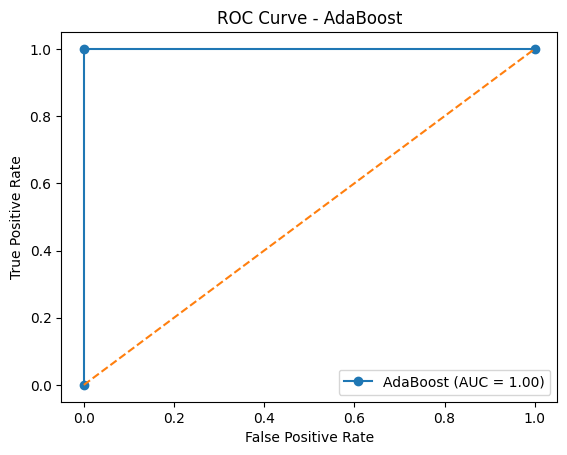

In [7]:

# -------------------------
# 5. AUC
# -------------------------
auc = roc_auc_score(y_test, y_prob)
print("AUC:", auc)

# -------------------------
# 6. Graficar ROC
# -------------------------
plt.plot(fpr, tpr, marker="o", label=f"AdaBoost (AUC = {auc:.2f})")
plt.plot([0, 1], [0, 1], linestyle="--")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - AdaBoost")
plt.legend()
plt.show()